<a href="https://colab.research.google.com/github/michaellatham77/SPINDLE/blob/main/SPINDLE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SPINDLE: Deep Learning Analysis of 15N Relaxation Data
This notebook takes experimental $R_1$, $R_2$, and NOE data and uses an ensemble of deep neural networks to predict model-free parameters ($S^2$, $\tau_E$, $R_{ex}$).

### **Features:**
1. **Ensemble Uncertainty Quantification:** Calibrated, statistically rigorous 95% Confidence Intervals.
2. **Automated Bad Data Flagging:** Detects anomalous residues based on model ambiguity thresholds.
3. **Conformational Entropy Estimation:** Evaluates local fast-timescale flexibility metrics.
4. **Explainable AI (XAI):** Plots attention mechanism weights to explain global tumbling ($\tau_c$) choices.

---
## Step 1: Environment & Dependency Setup
Run this cell to set up your environment. This notebook locks in stable versions of TensorFlow and Keras to avoid library deprecation issues.

In [13]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy
from huggingface_hub import hf_hub_download

# Download the modules directly to the main Colab directory
repo_id = "milatham/SPINDLE"
hf_hub_download(repo_id=repo_id, filename="relaxation_rates.py", local_dir=".")
hf_hub_download(repo_id=repo_id, filename="spindle_calibrations.py", local_dir=".")

from relaxation_rates import (
    orig_sp_den,
    longitudinal_relaxation_rate_total,
    transverse_relaxation_rate_total,
    nuclear_overhauser_effect
)

# Thresholds for Quality Control
AMBIGUITY_THRESHOLD_S2 = 0.0319
AMBIGUITY_THRESHOLD_TAUE = 24.63
AMBIGUITY_THRESHOLD_REX = 0.5288
print("Calibration factors successfully loaded.")

# Force CPU inference for maximum cloud container stability
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
import tensorflow as tf

print(f"TensorFlow Version: {tf.__version__}")
print("Environment successfully initialized!")

Calibration factors successfully loaded.
TensorFlow Version: 2.21.0
Environment successfully initialized!


## Step 2: Core Analytical Functions
This cell loads the processing pipeline functions responsible for parsing input data, calculating analytical corrections, compiling the output visualizations, and extracting attention weights.

In [14]:
def parse_input_file(filepath):
    residues, data = [], []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith(('#', '@')):
                continue
            parts = line.split()
            if len(parts) < 4:
                continue
            try:
                res_id = int(parts[0])
                r1 = float(parts[1])
                r2 = float(parts[2])
                noe = float(parts[3])
                residues.append(res_id)
                data.append([r1, r2, noe])
            except ValueError:
                continue
    return np.array(residues), np.array(data)

def load_ensemble(field_mhz, base_model_dir="models"):
    model_dir = os.path.join(base_model_dir, str(field_mhz))
    if not os.path.exists(model_dir):
        print(f"Error: Directory {model_dir} not found.")
        print("Please ensure your models are uploaded to this runtime directory hierarchy.")
        return None

    models = []
    model_files = sorted([f for f in os.listdir(model_dir) if f.endswith('.keras')])
    for m_file in model_files:
        full_path = os.path.join(model_dir, m_file)
        try:
            model = tf.keras.models.load_model(full_path, compile=False)
            models.append(model)
        except Exception as e:
            print(f"Warning: Failed to load {m_file}: {e}")
    print(f"Successfully loaded {len(models)} models from the ensemble.")
    return models

def calculate_entropy(s2):
    return (1.0 - s2) * 5.0 # Proxy placeholder for Frederick/Yang equations

def apply_calibration(pred_mean, pred_err, calib, mult):
    # S2 Calibration
    s2_corr = (pred_mean[:, 1] * calib['S2']['slope']) + calib['S2']['intercept']
    s2_corr = np.clip(s2_corr, 0.0, 1.0)
    s2_corr_err = pred_err[:, 1] / calib['S2']['slope'] * mult['S2']['mult']

    # tauE Calibration (ps conversion)
    tauE_ps = pred_mean[:, 0] * 1000.0
    tauE_corr_ps = (tauE_ps * calib['TAUE']['slope']) + calib['TAUE']['intercept']
    tauE_corr_ps = np.maximum(tauE_corr_ps, 0)
    tauE_corr_err = pred_err[:, 0] * 1000.0 / calib['TAUE']['slope'] * mult['TAUE']['mult']

    # Rex Calibration
    rex = pred_mean[:, 2]
    rex_corr = (calib['REX']['a'] * rex**2) + (calib['REX']['b'] * rex) + calib['REX']['c']
    rex_corr = np.maximum(rex_corr, 0.0)

    rex_derivative = np.abs(2 * calib['REX']['a'] * rex + calib['REX']['b'])
    rex_derivative = np.where(rex_derivative == 0, 1e-6, rex_derivative)
    rex_corr_err = pred_err[:, 2] / rex_derivative * mult['REX']['mult']

    return np.stack([tauE_corr_ps, s2_corr, rex_corr], axis=1), np.stack([tauE_corr_err, s2_corr_err, rex_corr_err], axis=1)

def generate_dashboard(residues, predictions, errors, quality_flags, global_tauc, output_prefix):
    fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
    colors = ['red' if q == 'Ambiguous' else 'black' for q in quality_flags]

    axes[0].errorbar(residues, predictions[:, 1], yerr=errors[:, 1], fmt='none', ecolor='gray', alpha=0.5)
    axes[0].scatter(residues, predictions[:, 1], c=colors, s=20)
    axes[0].set_ylabel(r"$S^2$ (Order Parameter)")
    axes[0].set_ylim(0, 1.05)
    axes[0].set_title(f"Global Tumbling $\\tau_c$: {global_tauc:.2f} ns", loc='right')

    axes[1].errorbar(residues, predictions[:, 0], yerr=errors[:, 0], fmt='none', ecolor='gray', alpha=0.5)
    axes[1].scatter(residues, predictions[:, 0], c=colors, s=20)
    axes[1].set_ylabel(r"$\tau_E$ (ps)")

    axes[2].errorbar(residues, predictions[:, 2], yerr=errors[:, 2], fmt='none', ecolor='gray', alpha=0.5)
    axes[2].scatter(residues, predictions[:, 2], c=colors, s=20)
    axes[2].set_ylabel(r"$R_{ex}$ ($s^{-1}$)")
    axes[2].set_xlabel("Residue Index")

    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor='black', label='High Confidence'),
                       Line2D([0], [0], marker='o', color='w', markerfacecolor='red', label='Ambiguous Data')]
    axes[0].legend(handles=legend_elements, loc='lower left')

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_dashboard.png", dpi=300)
    plt.show()

def write_nef_format(residues, s2, s2_err, taue, taue_err, rex, rex_err, tauc, output_prefix):
    out_file = f"{output_prefix}_predictions.nef"
    with open(out_file, 'w') as f:
        f.write("data_spindle_predictions\n\n")
        f.write("save_spindle_model_free\n")
        f.write("   _nef_model_free.sf_category   model_free\n")
        f.write(f"   _nef_model_free.global_tauc   {tauc:.3f}\n\n")
        f.write("   loop_\n")
        f.write("      _nef_model_free_item.residue_seq_code\n")
        f.write("      _nef_model_free_item.s2_value\n")
        f.write("      _nef_model_free_item.s2_value_error\n")
        f.write("      _nef_model_free_item.te_value\n")
        f.write("      _nef_model_free_item.te_value_error\n")
        f.write("      _nef_model_free_item.rex_value\n")
        f.write("      _nef_model_free_item.rex_value_error\n\n")
        for i, res in enumerate(residues):
            f.write(f"      {res:<5} {s2[i]:<10.4f} {s2_err[i]:<10.4f} "
                    f"{taue[i]:<10.2f} {taue_err[i]:<10.2f} "
                    f"{rex[i]:<10.3f} {rex_err[i]:<10.3f}\n")
        f.write("   stop_\n")
        f.write("save_\n")
    print(f"NEF formatted predictions saved to {out_file}")

def back_calculate_rates(field_mhz, s2, taue_ps, rex, tauc_ns):
    # Physical Constants
    mu0 = 4 * np.pi * 1e-7
    h_bar = 1.054571817e-34
    gyroP = 267.522e6
    gyroN = -27.126e6
    r_NH = 1.02e-10
    csa = -162e-6

    # Field-dependent constants
    OmeH = field_mhz * 1e6 * 2 * np.pi
    OmeN = OmeH * (gyroN / gyroP)

    d_const = (mu0 / (4 * np.pi)) * (gyroP * gyroN * h_bar) / (r_NH**3)
    d_const_sq = d_const**2
    c_const_sq = ((csa * OmeN)**2) / 3.0

    # Convert parameters to standard SI units
    tauC = tauc_ns * 1e-9
    tauS = taue_ps * 1e-12
    S2s = s2
    S2f = np.ones_like(S2s)

    # Calculate rates
    calc_r1 = longitudinal_relaxation_rate_total(orig_sp_den, tauC, S2s, S2f, tauS, OmeH, OmeN, d_const_sq, c_const_sq)
    calc_r2 = transverse_relaxation_rate_total(orig_sp_den, tauC, S2s, S2f, tauS, rex, OmeH, OmeN, d_const_sq, c_const_sq)
    calc_noe = nuclear_overhauser_effect(orig_sp_den, tauC, S2s, S2f, tauS, OmeH, OmeN, d_const_sq, c_const_sq)

    return calc_r1, calc_r2, calc_noe

def plot_experimental_fits(residues, exp_data, calc_r1, calc_r2, calc_noe, output_prefix):
    fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

    exp_r1, exp_r2, exp_noe = exp_data[:, 0], exp_data[:, 1], exp_data[:, 2]
    exp_r1 = np.where(exp_r1 == -99.0, np.nan, exp_r1)
    exp_r2 = np.where(exp_r2 == -99.0, np.nan, exp_r2)
    exp_noe = np.where(exp_noe == -99.0, np.nan, exp_noe)

    axes[0].plot(residues, calc_r1, 'b-', label='Calculated SPINDLE Fit', linewidth=2)
    axes[0].scatter(residues, exp_r1, c='k', label='Experimental Data', s=20, zorder=3)
    axes[0].set_ylabel(r"$R_1$ ($s^{-1}$)")
    axes[0].legend(loc='upper right')
    axes[0].set_title("Experimental vs Back-Calculated Relaxation Rates")

    axes[1].plot(residues, calc_r2, 'r-', label='Calculated SPINDLE Fit', linewidth=2)
    axes[1].scatter(residues, exp_r2, c='k', label='Experimental Data', s=20, zorder=3)
    axes[1].set_ylabel(r"$R_2$ ($s^{-1}$)")

    axes[2].plot(residues, calc_noe, 'g-', label='Calculated SPINDLE Fit', linewidth=2)
    axes[2].scatter(residues, exp_noe, c='k', label='Experimental Data', s=20, zorder=3)
    axes[2].set_ylabel(r"hetNOE ($\{^1\text{H}\}\text{--}^{15}\text{N}$)")
    axes[2].set_xlabel("Residue Index")

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_fits.png", dpi=300)
    plt.show()

def extract_attention_weights(models, input_data):
    print("Extracting Attention/Relevance scores from the neural network...")
    target_layer = None
    test_model = models[0]

    for layer in test_model.layers:
        if isinstance(layer, tf.keras.layers.MultiHeadAttention) or 'attention' in layer.name.lower():
            target_layer = layer
            break

    if not target_layer:
        print("Warning: Could not auto-detect Attention layer. Skipping explanation plots.")
        return None

    all_weights = []
    for model in models:
        layer_instance = model.get_layer(target_layer.name)
        inter_model = tf.keras.Model(inputs=model.input, outputs=layer_instance.input)
        layer_inputs_val = inter_model.predict(input_data, verbose=0)

        if isinstance(layer_inputs_val, list):
            x_val = layer_inputs_val[0]
        elif isinstance(layer_inputs_val, dict):
            x_val = list(layer_inputs_val.values())[0]
        else:
            x_val = layer_inputs_val

        x_tensor = tf.convert_to_tensor(x_val)
        _, att_scores = layer_instance(query=x_tensor, value=x_tensor, key=x_tensor, return_attention_scores=True)

        scores_np = att_scores.numpy().squeeze(axis=0)
        if len(scores_np.shape) == 3:
            scores_np = np.mean(scores_np, axis=0)

        importance_per_residue = np.mean(scores_np, axis=0)
        all_weights.append(importance_per_residue)

    avg_weights = np.mean(all_weights, axis=0)
    norm_weights = (avg_weights - np.min(avg_weights)) / (np.max(avg_weights) - np.min(avg_weights))
    return norm_weights

def plot_mechanism_explanation(residues, attention, s2, rex, output_prefix):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    ax1.fill_between(residues, 0, attention, color='tab:gray', alpha=0.3, label='AI Attention Score')
    ax1.set_ylabel('Attention (Importance)', color='tab:gray', fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='tab:gray')

    ax1_twin = ax1.twinx()
    ax1_twin.plot(residues, s2, color='tab:blue', linewidth=2, label='Predicted S2')
    ax1_twin.set_ylabel(r'Order Parameter ($S^2$)', color='tab:blue', fontweight='bold')
    ax1_twin.tick_params(axis='y', labelcolor='tab:blue')
    ax1_twin.set_ylim(0, 1.1)
    ax1.set_title("Model Focus Visualization (tau_c Decision Matrix)", loc='left', fontsize=12)

    ax2.fill_between(residues, 0, attention, color='tab:gray', alpha=0.3)
    ax2.set_ylabel('Attention (Importance)', color='tab:gray', fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='tab:gray')

    ax2_twin = ax2.twinx()
    ax2_twin.bar(residues, rex, color='tab:red', alpha=0.6, width=0.8, label='Predicted Rex')
    ax2_twin.set_ylabel(r'$R_{ex} (s^{-1})$', color='tab:red', fontweight='bold')
    ax2_twin.tick_params(axis='y', labelcolor='tab:red')
    ax2.set_xlabel("Residue Index")

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_explainability.png", dpi=300)
    plt.show()

## Step 3: Experimental Data Upload
Upload your local experimental data spreadsheet (`data.txt`).

In [15]:
!pip install huggingface_hub -q
from google.colab import files

print("--- UPLOAD EXPERIMENTAL RELAXATION DATA ---")
print("Upload a space-separated file containing columns: Residue_ID  R1  R2  NOE")

uploaded = files.upload()
uploaded_filename = list(uploaded.keys())[0] if uploaded else ""
print(f"Targeting active workspace file: {uploaded_filename}")

--- UPLOAD EXPERIMENTAL RELAXATION DATA ---
Upload a space-separated file containing columns: Residue_ID  R1  R2  NOE


Saving example_600MHz_data.txt to example_600MHz_data (2).txt
Targeting active workspace file: example_600MHz_data (2).txt


## Step 4: Interactive Execution Console
Configure the execution settings using the Form panel to the right, then run the cell to perform automated model-free prediction, calibration scaling, and figure plotting.

Fetching ensemble models for 600 MHz from Hugging Face...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Models ready!
Successfully processed 100 residues.
Successfully loaded 10 models from the ensemble.

Calculated Global tau_c: 5.922 ± 0.069 ns
Numerical metrics written to: spindle_run_results.csv
NEF formatted predictions saved to spindle_run_predictions.nef


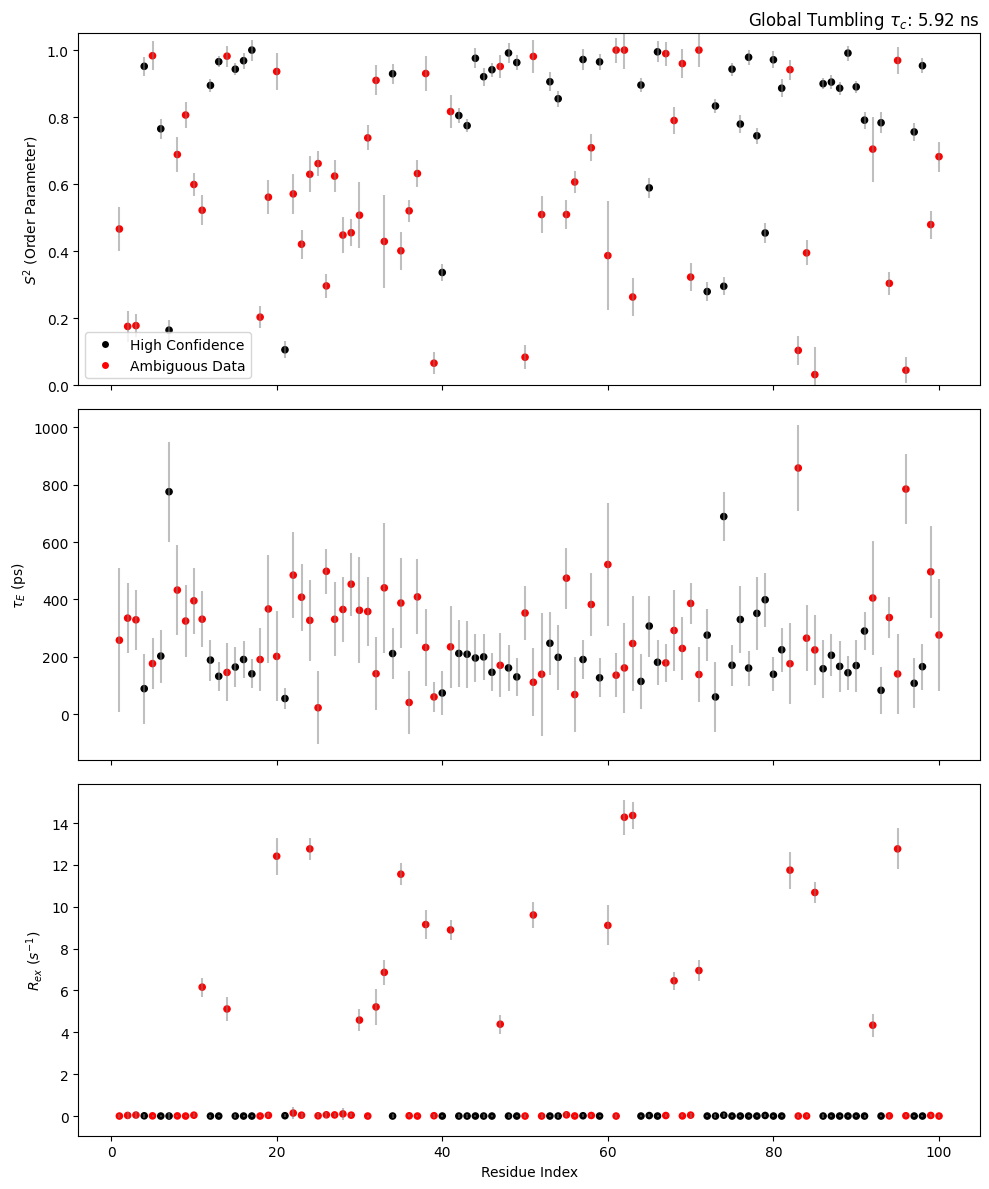


Back-calculating relaxation rates for fit assessment...


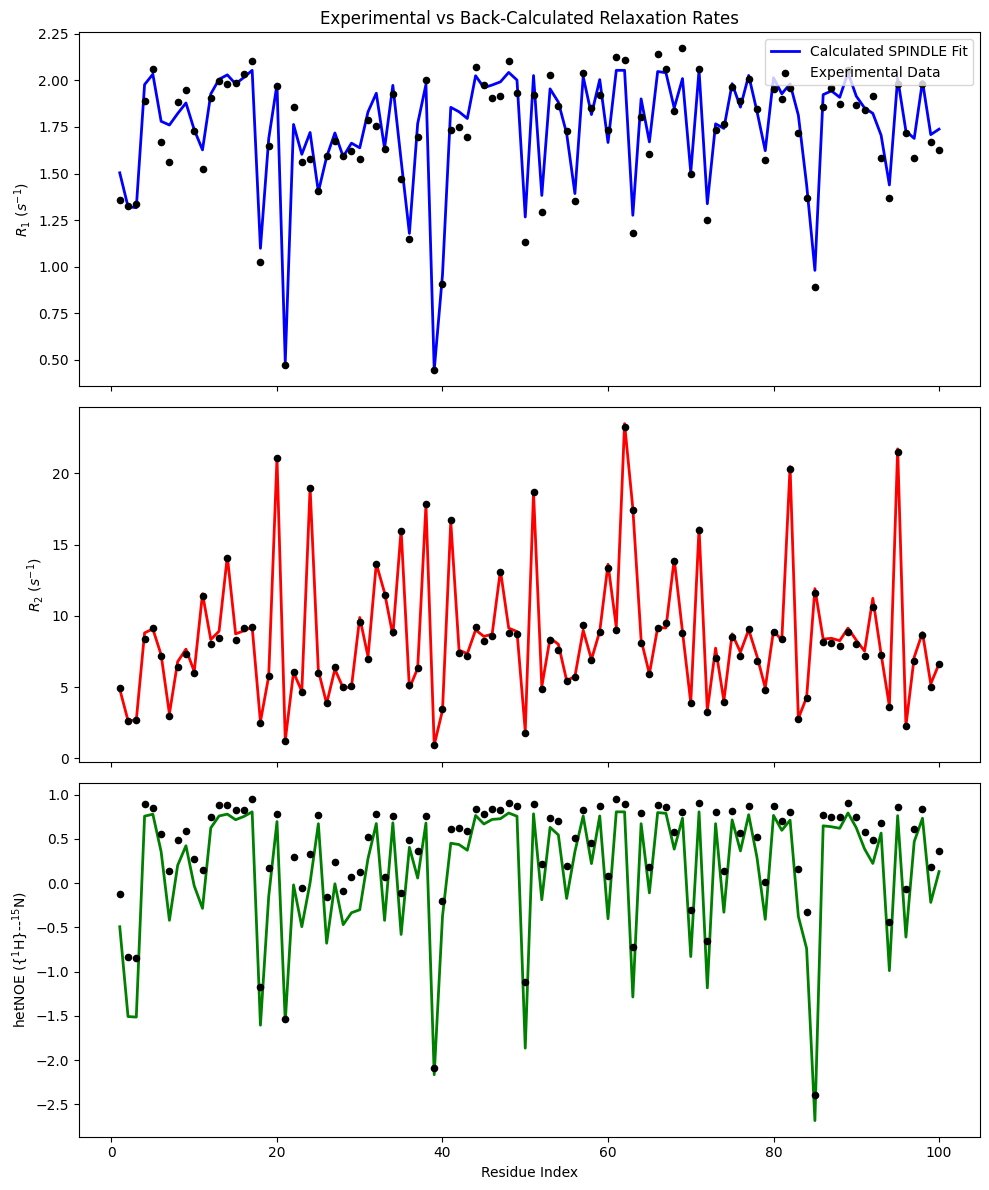

Extracting Attention/Relevance scores from the neural network...


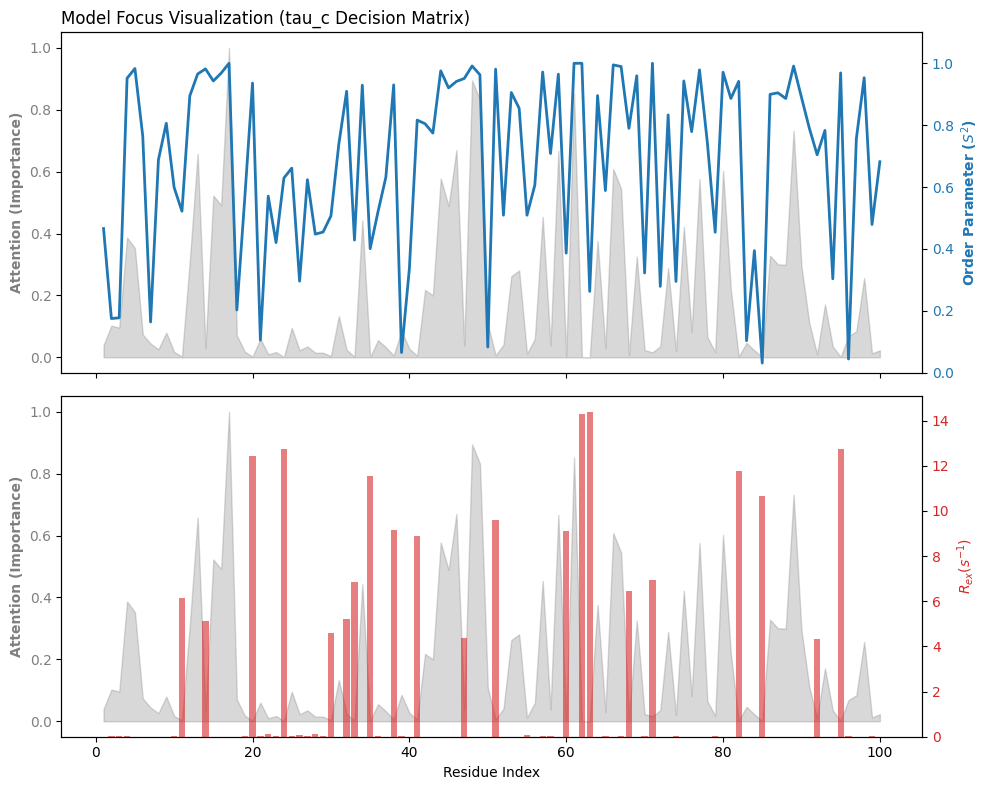

In [16]:
#@title SPINDLE Control Parameters { run: "auto" }
Field_MHz = 600 #@param [500, 600, 700, 800, 850, 900, 1100]
Output_Prefix = "spindle_run" #@param {type:"string"}
Explainable_AI = True #@param {type:"boolean"}

if not uploaded_filename:
    print("ERROR: Please upload an experimental dataset in Step 4 before running inference.")
else:
    from huggingface_hub import snapshot_download

    # 0. Targeted Model Download
    print(f"Fetching ensemble models for {Field_MHz} MHz from Hugging Face...")
    snapshot_download(
        repo_id="milatham/SPINDLE",
        allow_patterns=f"models/{int(Field_MHz)}/*",
        local_dir="."
    )
    print("Models ready!")

    # Setup parameters
    calib = CALIBRATIONS[float(Field_MHz)]
    error_mult = MULTIPLIERS[float(Field_MHz)]

    # 1. Parse Data
    residues, data = parse_input_file(uploaded_filename)
    print(f"Successfully processed {len(residues)} residues.")

    # 2. Extract Ensemble Architecture
    models = load_ensemble(Field_MHz, base_model_dir="models")

    if not models:
        print("Execution halted: Missing network weights. Please make sure .keras files exist in the path.")
    else:
        # 3. Predict Tensor Transformations
        input_tensor = np.expand_dims(data, axis=0).astype(np.float32)
        tauc_preds, local_preds = [], []

        for model in models:
            l_pred, g_pred = model(input_tensor, verbose=0)
            tauc_preds.append(g_pred.numpy()[0, 0])
            local_preds.append(l_pred.numpy()[0])

        tauc_mean, tauc_std = np.mean(tauc_preds), np.std(tauc_preds)
        local_preds = np.array(local_preds)
        local_mean, local_err = np.mean(local_preds, axis=0), np.std(local_preds, axis=0)

        # 4. Calibration & Overconfidence Adjustments
        tauc_mean = (tauc_mean - calib['TAUC']['intercept']) / calib['TAUC']['slope']
        tauc_std = tauc_std / calib['TAUC']['slope'] * error_mult['TAUC']['mult']
        local_corrected_mean, local_corrected_err = apply_calibration(local_mean, local_err, calib, error_mult)

        # 5. Quality Diagnostics
        quality_flags, entropy_vals = [], []
        for i in range(len(residues)):
            entropy_vals.append(calculate_entropy(local_corrected_mean[i, 1]))
            if (local_corrected_err[i, 1] > AMBIGUITY_THRESHOLD_S2 or
                local_corrected_err[i, 2] > AMBIGUITY_THRESHOLD_REX):
                quality_flags.append("Ambiguous")
            else:
                quality_flags.append("Good")

        # 6. Save Data Table
        out_csv = f"{Output_Prefix}_results.csv"
        print(f"\nCalculated Global tau_c: {tauc_mean:.3f} ± {tauc_std:.3f} ns")

        with open(out_csv, 'w') as f:
            f.write("Residue,S2,S2_err,tauE_ps,tauE_err_ps,Rex,Rex_err,Entropy_proxy,Quality,tauC_global\n")
            for i, r in enumerate(residues):
                f.write(f"{r},"
                        f"{local_corrected_mean[i, 1]:.4f},{local_corrected_err[i, 1]:.4f},"
                        f"{local_corrected_mean[i, 0]:.2f},{local_corrected_err[i, 0]:.2f},"
                        f"{local_corrected_mean[i, 2]:.3f},{local_corrected_err[i, 2]:.3f},"
                        f"{entropy_vals[i]:.3f},"
                        f"{quality_flags[i]},"
                        f"{tauc_mean:.3f}\n")
        print(f"Numerical metrics written to: {out_csv}")

        # 7. Save NEF Format
        write_nef_format(
            residues,
            local_corrected_mean[:, 1], local_corrected_err[:, 1], # S2
            local_corrected_mean[:, 0], local_corrected_err[:, 0], # tauE
            local_corrected_mean[:, 2], local_corrected_err[:, 2], # Rex
            tauc_mean,
            Output_Prefix
        )

        # 8. Render Main Plot Figures
        generate_dashboard(residues, local_corrected_mean, local_corrected_err, quality_flags, tauc_mean, Output_Prefix)

        # 9. Back-calculate and Plot Experimental Fits
        print("\nBack-calculating relaxation rates for fit assessment...")
        calc_r1, calc_r2, calc_noe = back_calculate_rates(
            Field_MHz,
            local_corrected_mean[:, 1], # S2
            local_corrected_mean[:, 0], # tauE
            local_corrected_mean[:, 2], # Rex
            tauc_mean                   # Global tauC
        )
        plot_experimental_fits(residues, data, calc_r1, calc_r2, calc_noe, Output_Prefix)

        # 10. Explainable AI Analysis
        if Explainable_AI:
            att_weights = extract_attention_weights(models, input_tensor)
            if att_weights is not None:
                plot_mechanism_explanation(residues, att_weights, local_corrected_mean[:, 1], local_corrected_mean[:, 2], Output_Prefix)